# Results-Baseline

In [35]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

In [2]:
# define number of group splits
cv = GroupKFold(n_splits=5)
parameter_type = "tuned"  # "default"

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


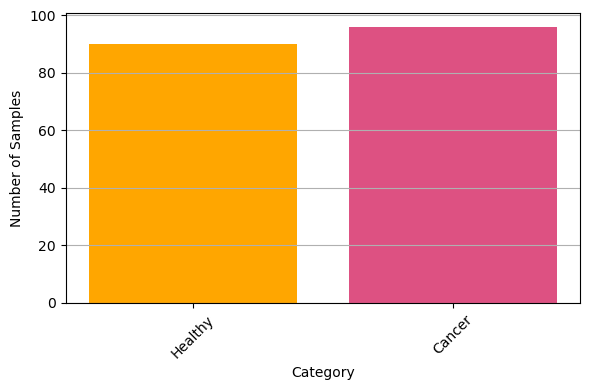


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [3]:
class_task = "healthy_vs_cancer"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [4]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=10.0, probability=True)

# select freq and IIVV and shape data
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [5]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [6]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

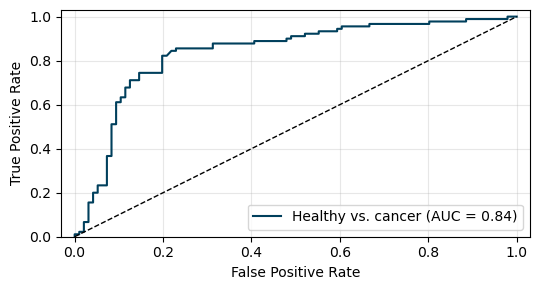

In [7]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

**RF**

In [8]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=5,
        min_samples_leaf=1,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [9]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [10]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

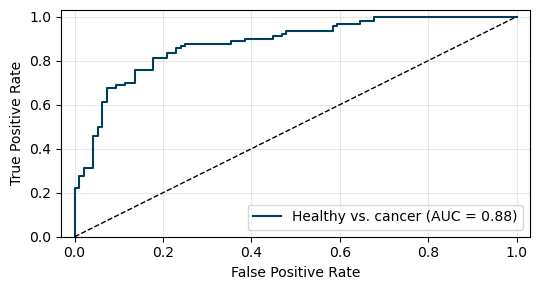

In [11]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

**LR**

In [12]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [13]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [14]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

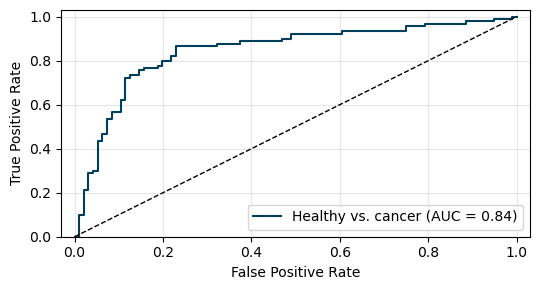

In [15]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

## Task 2 : Cancer versus HBD


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. HDB

Non-cancer: 162 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Non-cancer']
Coding: -> forward
{'Cancer': [1, 0], 'Non-cancer': [0, 1]}


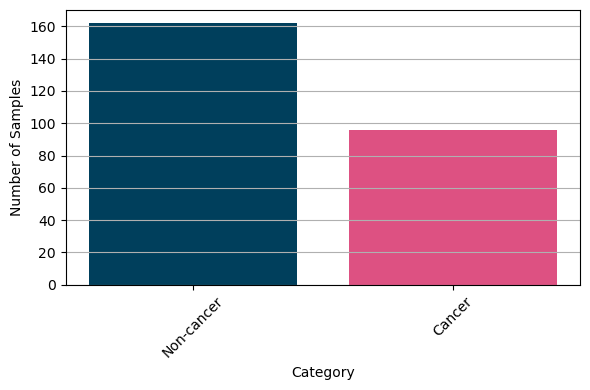


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Non-cancer'}
(258, 31, 7728) (258, 2) (258,)


In [16]:
class_task = "cancer_vs_hbd"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [17]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.001, probability=True, random_state=0)
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [18]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [19]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

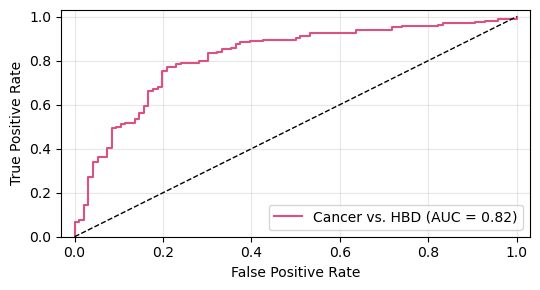

In [20]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

**RF**

In [21]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=4,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [22]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [23]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

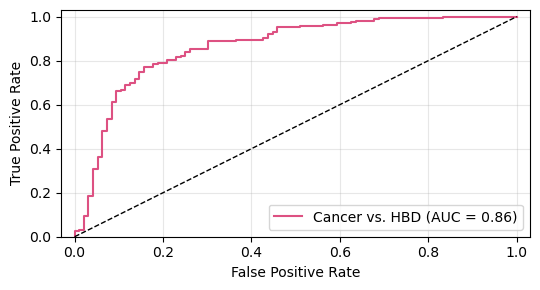

In [24]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

**LR**

In [25]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [26]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [27]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

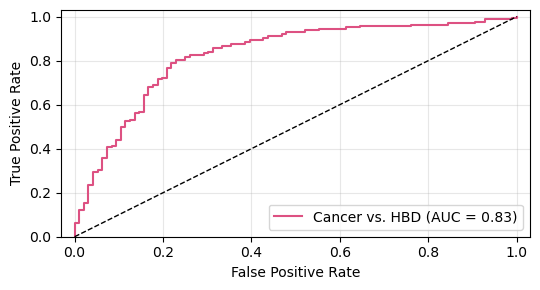

In [28]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

## Task 3: Multiclass

In [36]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade Dysplasia: 0 entries
Non-malignant: 0 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


**SVM**

In [30]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [31]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [32]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

In [33]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

KeyError: 'MC'

<Figure size 550x300 with 0 Axes>

**RF**

In [ ]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=1,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [ ]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [ ]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

In [ ]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

**LR**

In [ ]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=1.0, max_iter=1000)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [ ]:
y_true = []
y_score = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    t0 = time.time()
    probs = m.predict_proba(X_test)
    t1 = time.time()
    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

In [ ]:
np.savez(
    f"results/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

In [ ]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

___